<div dir="rtl" style="text-align: center;">
  <h1 style="color: #9e0059; font-family: B Titr; font-size: 68px;">
    Random variables & CLT
  </h1>
  <h1 style="color: #8660a9; font-family: B Titr; font-size: 40px;">
    داده‌کاوی
  </h1>
  <h1 style="color: #8660a9; font-family: B Titr; font-size: 32px;">
    استاد درس: دکتر رضازادگان | دستیار آموزشی: کیانا آشفته فرد
  </h1>
</div>



<div ><font color="#9e0059" face="B Titr">

# Lib

</div>

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

<div ><font color="#9e0059" face="B Titr">

# Bernoulli and Binomial

</div>

<div dir = "rtl"><font face = "B Nazanin" size = 5>
توزیع برنولی: زمانی استفاده می شود که در یک آزمایش تصادفی فقط دو نتیجه ممکن داشته باشیم؛ یکی از نتایج نشان دهنده موفقیت و دیگری نشان دهنده شکست است. موفقیت را با ۱ و شکست را با ۰ نشان می دهیم و احتمال موفقیت را با p مشخص می کنیم. برای مثال، بررسی کنیم که یک مشتری از فروشگاه خرید می کند یا نه.
<br><br>
توزیع دوجمله ای: زمانی استفاده می شود که یک آزمایش برنولی را به تعداد مشخصی (n) تکرار کنیم و بخواهیم تعداد موفقیت ها را بشماریم. در این حالت، آزمایش ها مستقل هستند و احتمال موفقیت در همه آن ها یکسان است. برای مثال، بررسی کنیم از بین ۱۰ مشتری، چند نفر خرید می کنند.

</font></div>

In [15]:
# np.random.seed(42)
np.random.binomial(n=1, p=0.25, size=1)

array([0], dtype=int32)

In [16]:
np.random.seed(42)
bernoulli_trials = np.random.binomial(1, 0.25, size=5)
bernoulli_trials

array([0, 1, 0, 0, 0], dtype=int32)

In [17]:
np.random.binomial(n=10, p=0.25) # X ~ Binomial(n=10, p=0.25)


1

In [18]:
np.random.binomial(10, 0.25, 5) # x1,x2,x3,x4,x5 ~ Binomial(10, 0.25)


array([1, 4, 3, 3, 0], dtype=int32)

In [19]:
success_counts = np.random.binomial(n = 10, p = 0.25, size=100)
success_counts

array([5, 4, 1, 1, 1, 2, 2, 2, 2, 3, 1, 2, 2, 2, 4, 1, 2, 3, 0, 3, 1, 1,
       5, 5, 4, 2, 1, 3, 2, 1, 2, 0, 4, 2, 3, 2, 2, 3, 1, 5, 3, 5, 4, 3,
       5, 1, 1, 0, 2, 2, 2, 4, 2, 2, 3, 1, 4, 1, 6, 3, 1, 0, 4, 3, 3, 3,
       1, 2, 1, 4, 3, 2, 1, 2, 2, 3, 3, 4, 2, 1, 3, 3, 3, 3, 2, 2, 2, 0,
       1, 0, 3, 2, 2, 4, 2, 2, 3, 1, 1, 2], dtype=int32)

In [20]:
frequencies = np.bincount(success_counts, minlength=10 + 1)
frequencies

array([ 6, 22, 32, 22, 11,  6,  1,  0,  0,  0,  0])

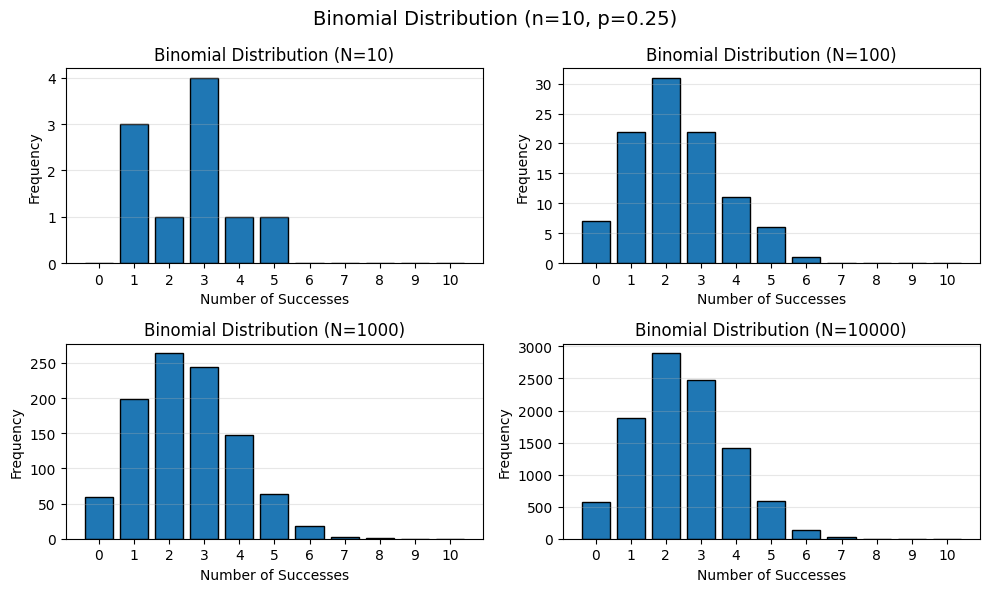

In [21]:
np.random.seed(42)
p = 0.25
n = 10
N_values = [10, 100, 1000, 10000]

plt.figure(figsize=(10, 6))

for i, N in enumerate(N_values):
    plt.subplot(2, 2, i + 1)

    success_counts = np.random.binomial(n, p, size=N)
    frequencies = np.bincount(success_counts, minlength=n + 1)

    plt.bar(range(n + 1), frequencies, edgecolor="black", width=0.8)
    plt.xlabel("Number of Successes")
    plt.ylabel("Frequency")
    plt.title(f"Binomial Distribution (N={N})")
    plt.xticks(range(n + 1))
    plt.grid(axis="y", alpha=0.3)

plt.suptitle(f"Binomial Distribution (n={n}, p={p})", fontsize=14)
plt.tight_layout()
plt.show()

<div ><font color="#9e0059" face="B Titr">

# Central Limit Theorem

</div>

<div dir="rtl" style="font-family: 'B Nazanin'; font-size: 20px; text-align: right; line-height: 1.9;">

اگر متغیرهای تصادفی &lrm;X₁, X₂, …, Xₙ&lrm; مستقل و هم‌توزیع باشند و میانگین &lrm;μ&lrm; و واریانس &lrm;σ²&lrm; داشته باشند، برای &lrm;n&lrm; به اندازه کافی بزرگ داریم:

</div>

$$
\overline{X}_n \approx N\left(\mu, \frac{\sigma^2}{n}\right)
$$

<div dir="rtl" style="font-family: 'B Nazanin'; font-size: 20px; text-align: right; line-height: 1.9;">

به این معنی که توزیع میانگین نمونه تقریباً نرمال است، با میانگین &lrm;μ&lrm; و واریانس برابر با:

</div>

$$
\frac{\sigma^2}{n}
$$

<div ><font color="#9e0059" face="B Titr">

## Binomial

</div>

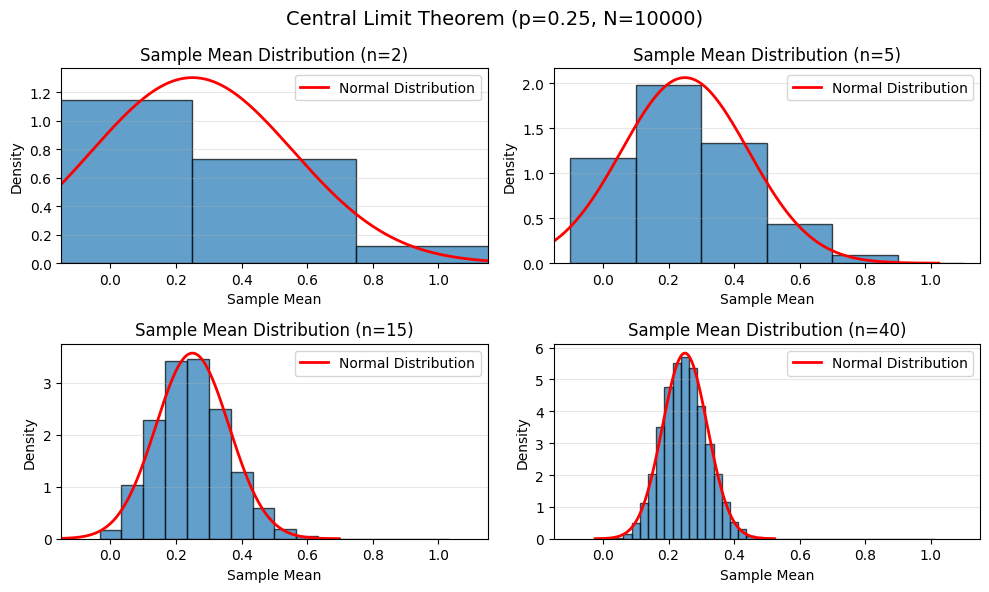

In [23]:
np.random.seed(42)

p = 0.25
N = 10000
n_values = [2, 5, 15, 40]

plt.figure(figsize=(10, 6))

for i, n in enumerate(n_values):
    plt.subplot(2, 2, i + 1)

    sample_means = np.random.binomial(n, p, size=N) / n # p

    mu = p
    sigma = np.sqrt(p * (1 - p) / n)
    
    x_curve = np.linspace(mu - 4*sigma, mu + 4*sigma, 400)
    bins = np.arange(-0.5, n + 1.5, 1) / n

    plt.hist(
        sample_means,
        bins=bins,
        density=True,
        edgecolor="black",
        alpha=0.7
    )

    plt.plot(
        x_curve,
        norm.pdf(x_curve, loc=mu, scale=sigma),
        color="red",
        linewidth=2,
        label="Normal Distribution"
    )

    plt.xlabel("Sample Mean")
    plt.ylabel("Density")
    plt.title(f"Sample Mean Distribution (n={n})")
    plt.xlim(-0.15, 1.15)
    plt.grid(axis="y", alpha=0.3)
    plt.legend()

plt.suptitle(
    f"Central Limit Theorem (p={p}, N={N})",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [13]:
n=2
np.arange(-0.5, n + 1.5, 1) / n

array([-0.25,  0.25,  0.75,  1.25])

<div ><font color="#9e0059" face="B Titr">

## Uniform

</div>

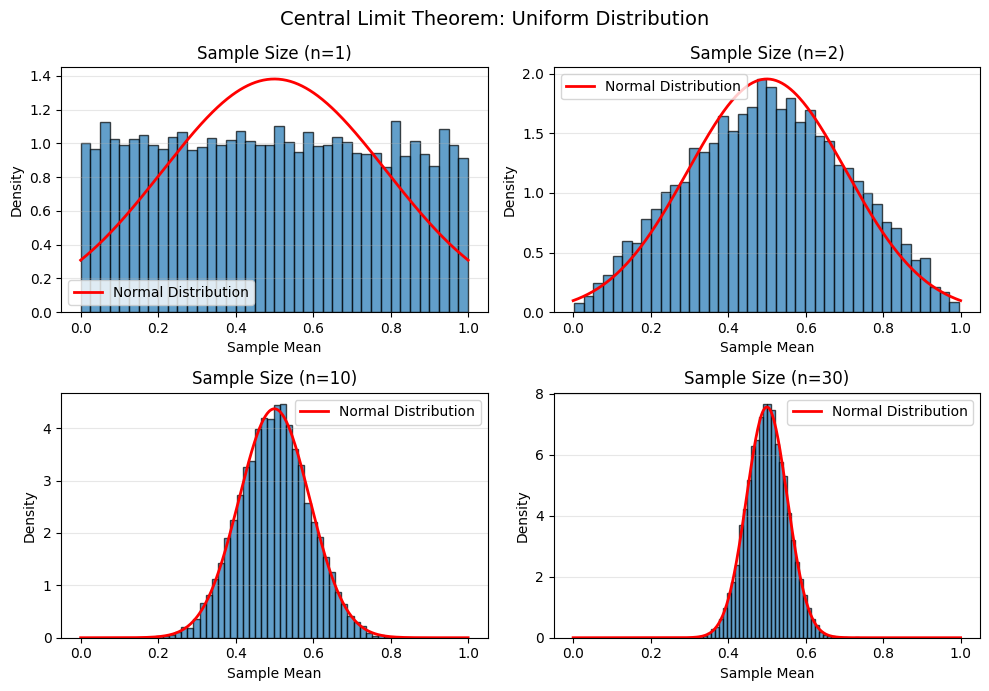

In [25]:
np.random.seed(42)

N = 10000
sample_sizes = [1, 2, 10, 30]

plt.figure(figsize=(10, 7))

for i, n in enumerate(sample_sizes):
    plt.subplot(2, 2, i + 1)

    sample_means = [np.mean(np.random.uniform(0, 1, n)) for _ in range(N)]

    # samples = np.random.uniform(0, 1, size=(N, n))
    # sample_means = samples.mean(axis=1)

    mu = 0.5 # (a+b)/2
    sigma = np.sqrt(1 / (12 * n)) # sigma^2 = (b-a)^2 / 12
    x = np.linspace(0, 1, 400)

    plt.hist(sample_means, bins=40, density=True, edgecolor="black", alpha=0.7)
    plt.plot(x, norm.pdf(x, loc=mu, scale=sigma), color="red", linewidth=2, label="Normal Distribution")

    plt.xlabel("Sample Mean")
    plt.ylabel("Density")
    plt.title(f"Sample Size (n={n})")
    plt.legend()
    plt.grid(axis="y", alpha=0.3)

plt.suptitle("Central Limit Theorem: Uniform Distribution", fontsize=14)
plt.tight_layout()
plt.show()

<div ><font color="#9e0059" face="B Titr">


## Poisson

</div>

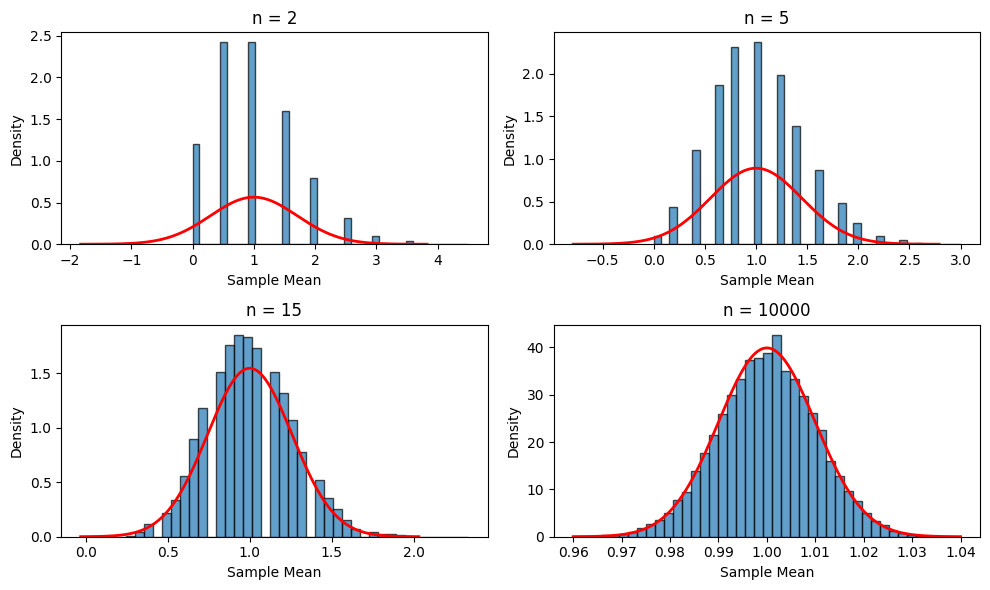

In [ ]:
np.random.seed(42)

lam = 1
N = 10000
n_values = [2, 5, 15, 10000]

plt.figure(figsize=(10, 6))

for i, n in enumerate(n_values):
    plt.subplot(2, 2, i + 1)

    samples = np.random.poisson(lam, size=(N, n))
    sample_means = samples.mean(axis=1)

    mu = lam
    sigma = np.sqrt(lam / n)
    x = np.linspace(mu - 4*sigma, mu + 4*sigma, 400)

    plt.hist(sample_means, bins=40, density=True, edgecolor="black", alpha=0.7)
    plt.plot(x, norm.pdf(x, mu, sigma), color="red", linewidth=2)

    plt.title(f"n = {n}")
    plt.xlabel("Sample Mean")
    plt.ylabel("Density")

plt.tight_layout()
plt.show()

In [ ]:
# N=1000000
# n=1
# x=c()
# M=c()
# while(n<=N){
#  x[n]=runif(n)
#  M[n]=(mean(x)-(1/2))/sqrt((1/12)/n)
#  hist(M)

#  n=n+1
# }

<div ><font color="#9e0059" face="B Titr">

# Exercise2
</div>

<div dir="rtl" style="font-family: 'B Nazanin'; font-size: 20px; text-align: right; line-height: 1.9;">

در کشور بحرین میانگین قد مردان 165.1 سانتی‌متر و انحراف از معیار نیز 9 سانتی‌متر است. چند درصد بحرینی‌ها قدشان بین  180 و 190 سانتی‌متر است؟
</div>

In [3]:
mean = 165.1
std = 9

percent = (norm.cdf(190, mean, std) - norm.cdf(180, mean, std)) * 100
percent

np.float64(4.607429708156241)